# Knapsack Problem: Experimental Analysis

This notebook presents an experimental study of several algorithms for the **0/1 Knapsack Problem**.  
The primary goal is to **analyze time complexity and solution quality** across different input sizes.

### Algorithms Evaluated
- Brute Force (Exact)
- Greedy Heuristics:
  - By Value
  - By Weight
  - By Value/Weight Ratio
- Dynamic Programming:
  - Bottom-Up
  - Top-Down (Memoized)
- Branch and Bound

### Evaluation Focus
- Practical runtime behavior
- Solution quality compared to optimal
- Scalability with respect to problem size


In [77]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("../src"))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

from src.generator import generate_instance
from src.utils import (
    pretty_print_instance,
    weight_of_solution,
    timeit,
    value_of_solution,
)
print("Notebook ready.")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Notebook ready.


In [78]:
from src.generator import generate_instance
from src.brute_force import brute_force
from src.greedy import greedy_by_value, greedy_by_weight, greedy_by_ratio
from src.dp import dp_bottom_up_reconstruct, dp_top_down_reconstruct
from src.branch_and_bound import branch_and_bound
from src.utils import timeit, weight_of_solution

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()


## Dataset Generation

Random knapsack instances are generated for multiple sizes of `n`:

- n = 10, 20, 25, 60, 100, 150

Each item is represented as:
- Value
- Weight
- Unique index

The knapsack capacity is derived from the generated instance.
A fixed random seed is used to ensure **reproducibility** of results.


In [83]:
sizes = [10,20,25, 60, 100, 150]

# store all generated datasets
datasets = {}

for n in sizes:
    items, capacity = generate_instance(n, seed=0)
    datasets[n] = (items, capacity)


In [84]:
for n in sizes:
    items, capacity = datasets[n]
    print(f"\n=== DATASET (n={n}) ===")
    print("Capacity:", capacity)
    print("Items (value, weight, index):")
    print(items[:10], "...")  # show first 10 items only



=== DATASET (n=10) ===
Capacity: 325
Items (value, weight, index):
[(45, 71, 0), (48, 89, 1), (65, 89, 2), (68, 13, 3), (68, 59, 4), (10, 66, 5), (84, 40, 6), (22, 88, 7), (37, 47, 8), (88, 89, 9)] ...

=== DATASET (n=20) ===
Capacity: 539
Items (value, weight, index):
[(45, 82, 0), (48, 38, 1), (65, 26, 2), (68, 78, 3), (68, 73, 4), (10, 10, 5), (84, 21, 6), (22, 81, 7), (37, 70, 8), (88, 80, 9)] ...

=== DATASET (n=25) ===
Capacity: 594
Items (value, weight, index):
[(45, 10, 0), (48, 21, 1), (65, 81, 2), (68, 70, 3), (68, 80, 4), (10, 48, 5), (84, 65, 6), (22, 83, 7), (37, 100, 8), (88, 89, 9)] ...

=== DATASET (n=60) ===
Capacity: 1514
Items (value, weight, index):
[(45, 18, 0), (48, 80, 1), (65, 5, 2), (68, 43, 3), (68, 59, 4), (10, 32, 5), (84, 2, 6), (22, 66, 7), (37, 42, 8), (88, 58, 9)] ...

=== DATASET (n=100) ===
Capacity: 2503
Items (value, weight, index):
[(45, 50, 0), (48, 70, 1), (65, 42, 2), (68, 36, 3), (68, 65, 4), (10, 96, 5), (84, 70, 6), (22, 95, 7), (37, 1, 8), (

In [85]:
def print_result_block(name, value, weight, capacity, sol, runtime):
    print(f"\n=== {name} ===")
    print(f"Value: {value}")
    print(f"Weight Used: {weight}/{capacity}")
    print(f"Items Selected: {sol}")
    print(f"Runtime: {round(runtime, 6)} s")


In [86]:
def plot_selected_items(items, sol, title):
    selected = set(sol)

    sel_vals = [v for (v,w,i) in items if i in selected]
    sel_wgts = [w for (v,w,i) in items if i in selected]

    non_vals = [v for (v,w,i) in items if i not in selected]
    non_wgts = [w for (v,w,i) in items if i not in selected]

    plt.figure(figsize=(8,6))
    plt.scatter(non_wgts, non_vals, s=40, color="lightgray", label="Not Selected")
    plt.scatter(sel_wgts, sel_vals, s=60, color="dodgerblue", label="Selected Items")
    plt.xlabel("Weight")
    plt.ylabel("Value")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


## Brute Force Algorithm

The brute force approach enumerates **all possible subsets** of items and guarantees an optimal solution.

### Characteristics
- Exact algorithm
- Exponential time complexity: **O(2ⁿ)**
- Practical only for very small `n`

### Experimental Setup
Due to its computational cost, brute force is executed **only for n ≤ 30**.
This provides a ground truth for evaluating heuristic and approximate methods.


In [87]:
results_bruteforce = []
for n in sizes:
    if n <=30:
        items, capacity = datasets[n]
        
        print(f"      BRUTE FORCE RESULTS (n={n})")
        items, capacity = datasets[n]

        t_bf, (bf_val, bf_sol) = timeit(brute_force)(items, capacity)
        bf_weight = weight_of_solution(items, bf_sol)

        # print("Value:", bf_val)
        # print("Weight:", f"{bf_weight}/{capacity}")
        # print("Solution:", bf_sol)
        # print("Runtime:", round(t_bf, 4), "seconds")

        results_bruteforce.append({
            "n": n,
            "value": bf_val,
            "weight": bf_weight,
            "time": t_bf,
            "solution": bf_sol
        })
print("BruteForce algorithms computed successfully.")

      BRUTE FORCE RESULTS (n=10)
      BRUTE FORCE RESULTS (n=20)
      BRUTE FORCE RESULTS (n=25)
BruteForce algorithms computed successfully.



=== Brute Force (n=10) ===
Value: 390
Weight Used: 319/325
Items Selected: [0, 3, 4, 6, 8, 9]
Runtime: 0.001109 s


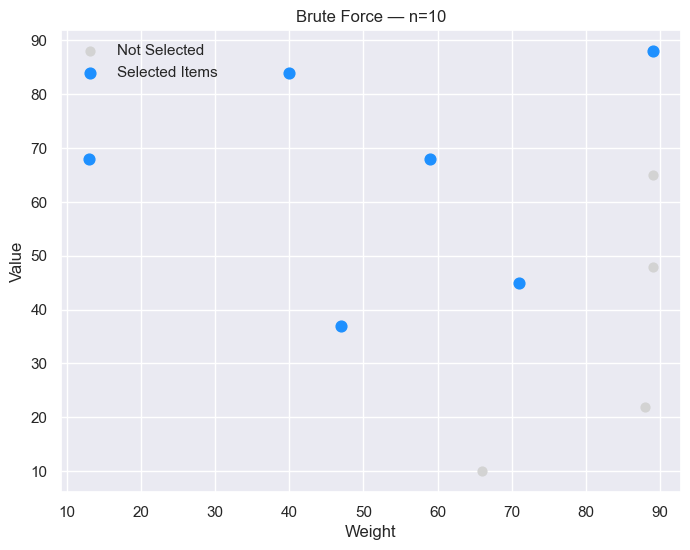


=== Brute Force (n=20) ===
Value: 892
Weight Used: 539/539
Items Selected: [1, 2, 4, 6, 9, 10, 11, 12, 15, 17, 18, 19]
Runtime: 2.472013 s


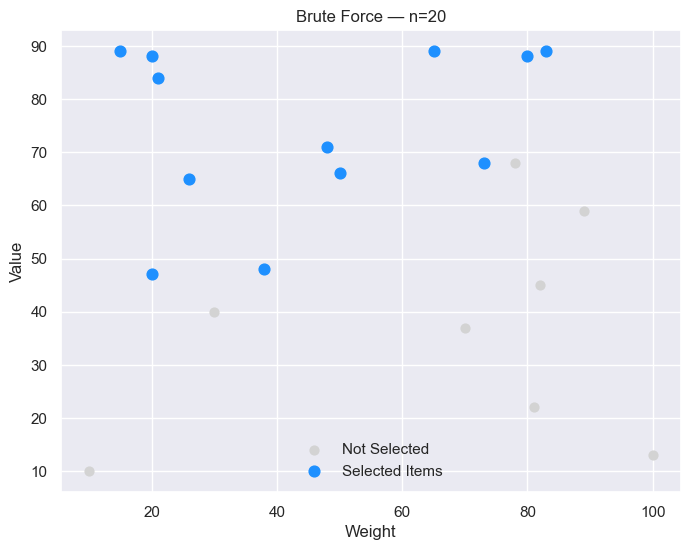


=== Brute Force (n=25) ===
Value: 1116
Weight Used: 581/594
Items Selected: [0, 1, 3, 6, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 24]
Runtime: 122.232937 s


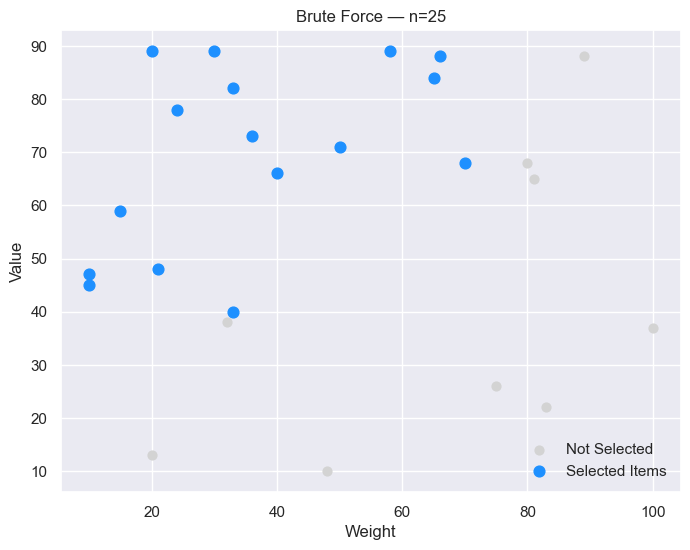

In [88]:
for row in results_bruteforce:
    n = row["n"]
    items, capacity = datasets[n]

    print_result_block(
        f"Brute Force (n={n})",
        row["value"],
        weight_of_solution(items, row["solution"]),
        capacity,
        row["solution"],
        row["time"]
    )

    plot_selected_items(items, row["solution"], f"Brute Force — n={n}")


## Greedy Heuristics

Greedy algorithms construct solutions incrementally using simple selection rules.

### Implemented Variants
- Greedy by Value
- Greedy by Weight
- Greedy by Value/Weight Ratio

### Properties
- Very fast in practice (near-linear time)
- No optimality guarantee
- Solution quality depends heavily on heuristic choice

These methods highlight the trade-off between **speed and optimality**.


In [89]:
greedy_results = []

for n in sizes:
    items, capacity = datasets[n]

    # compute 3 greedy methods
    t_gv, (gv_val, gv_sol) = timeit(greedy_by_value)(items, capacity)
    t_gw, (gw_val, gw_sol) = timeit(greedy_by_weight)(items, capacity)
    t_gr, (gr_val, gr_sol) = timeit(greedy_by_ratio)(items, capacity)

    greedy_results.append({
        "n": n,
        "gv_val": gv_val, "gv_sol": gv_sol, "gv_time": t_gv,
        "gw_val": gw_val, "gw_sol": gw_sol, "gw_time": t_gw,
        "gr_val": gr_val, "gr_sol": gr_sol, "gr_time": t_gr,
        "capacity": capacity
    })

print("Greedy algorithms computed successfully.")


Greedy algorithms computed successfully.



      GREEDY RESULTS (n=10)


=== Greedy by Value (n=10) ===
Value: 373
Weight Used: 290/325
Items Selected: [9, 6, 3, 4, 2]
Runtime: 1.2e-05 s

=== Greedy by Weight (n=10) ===
Value: 312
Weight Used: 296/325
Items Selected: [3, 6, 8, 4, 5, 0]
Runtime: 6e-06 s

=== Greedy by Ratio (n=10) ===
Value: 390
Weight Used: 319/325
Items Selected: [3, 6, 4, 9, 8, 0]
Runtime: 7e-06 s


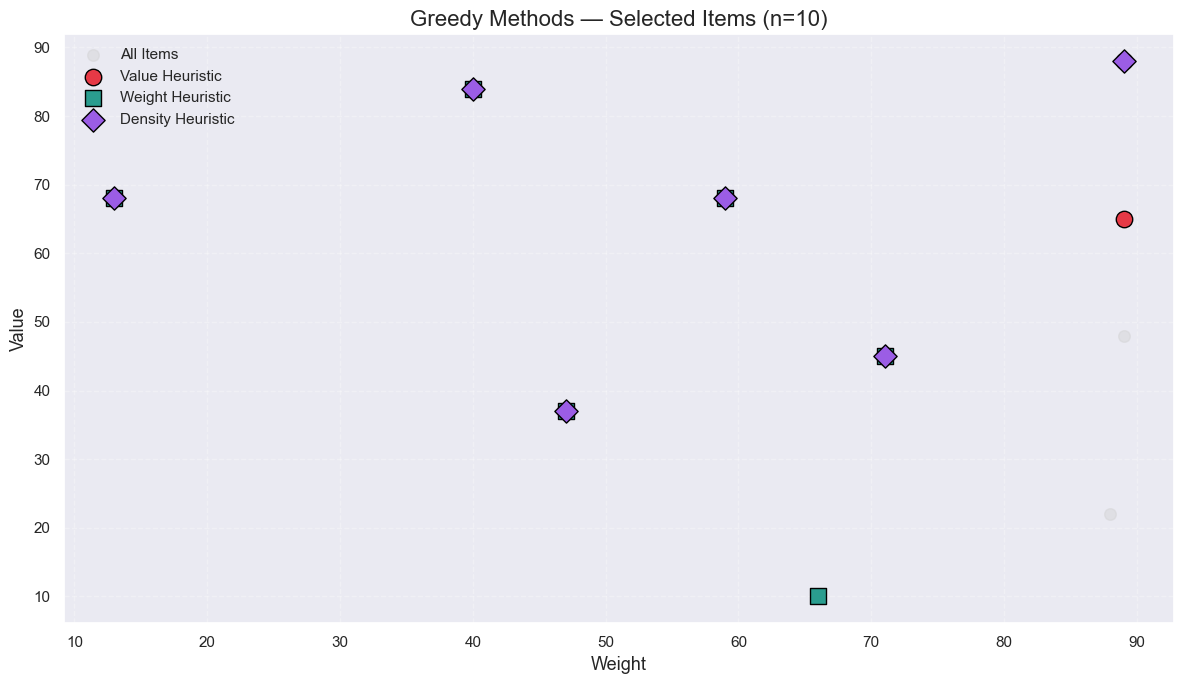


      GREEDY RESULTS (n=20)


=== Greedy by Value (n=20) ===
Value: 800
Weight Used: 533/539
Items Selected: [11, 12, 19, 9, 17, 6, 10, 3, 4, 15]
Runtime: 1e-05 s

=== Greedy by Weight (n=20) ===
Value: 802
Weight Used: 486/539
Items Selected: [5, 19, 17, 18, 6, 2, 16, 1, 10, 15, 11, 8, 4]
Runtime: 9e-06 s

=== Greedy by Ratio (n=20) ===
Value: 874
Weight Used: 506/539
Items Selected: [19, 17, 6, 2, 18, 10, 11, 16, 15, 1, 9, 12, 5]
Runtime: 1.1e-05 s


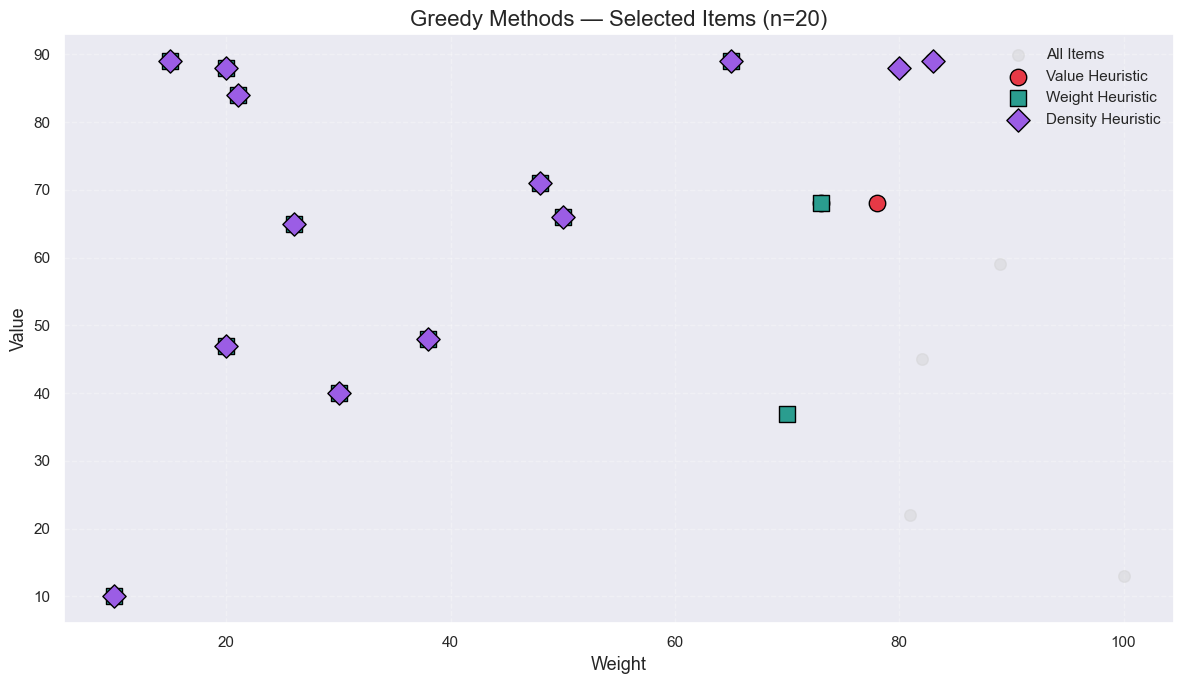


      GREEDY RESULTS (n=25)


=== Greedy by Value (n=25) ===
Value: 1012
Weight Used: 591/594
Items Selected: [11, 12, 19, 9, 17, 6, 20, 23, 24, 10, 3, 15, 18]
Runtime: 1.4e-05 s

=== Greedy by Weight (n=25) ===
Value: 1021
Weight Used: 545/594
Items Selected: [0, 18, 14, 12, 13, 1, 23, 11, 21, 16, 20, 24, 15, 5, 10, 19, 6]
Runtime: 1e-05 s

=== Greedy by Ratio (n=25) ===
Value: 1099
Weight Used: 563/594
Items Selected: [18, 0, 12, 14, 23, 11, 20, 1, 24, 15, 19, 10, 17, 6, 16, 21, 13]
Runtime: 1.4e-05 s


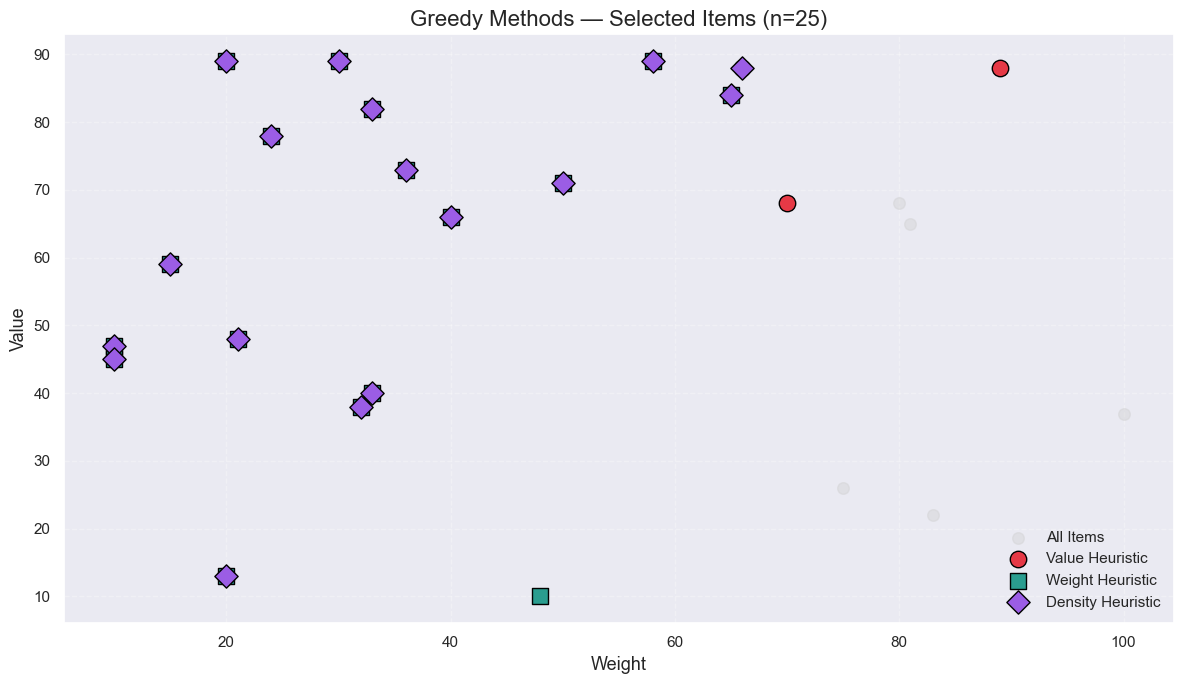


      GREEDY RESULTS (n=60)


=== Greedy by Value (n=60) ===
Value: 2328
Weight Used: 1511/1514
Items Selected: [33, 11, 12, 19, 34, 9, 17, 6, 32, 20, 27, 29, 23, 50, 47, 24, 10, 28, 3, 4, 15, 42, 2, 31, 14, 44, 51, 57, 35, 1, 30, 18, 48, 54]
Runtime: 2.5e-05 s

=== Greedy by Weight (n=60) ===
Value: 2197
Weight Used: 1484/1514
Items Selected: [15, 48, 6, 27, 54, 2, 24, 11, 19, 37, 16, 31, 0, 32, 58, 35, 5, 51, 10, 43, 50, 8, 42, 3, 20, 56, 12, 26, 39, 52, 40, 49, 29, 18, 9, 4, 34, 44, 7, 23, 25, 41]
Runtime: 2.4e-05 s

=== Greedy by Ratio (n=60) ===
Value: 2433
Weight Used: 1511/1514
Items Selected: [15, 6, 48, 27, 2, 24, 11, 19, 31, 32, 16, 0, 35, 50, 10, 20, 12, 51, 3, 42, 9, 29, 34, 37, 4, 23, 33, 28, 44, 8, 17, 18, 56, 40, 47, 49, 57, 58]
Runtime: 2.8e-05 s


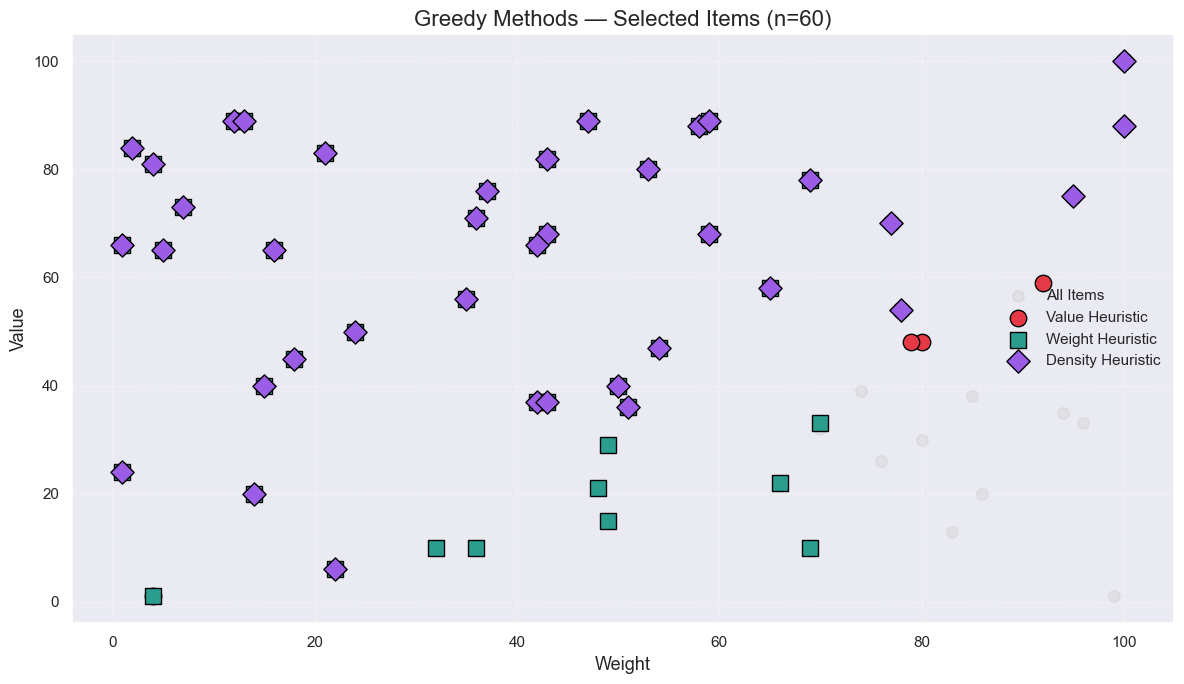


      GREEDY RESULTS (n=100)


=== Greedy by Value (n=100) ===
Value: 3806
Weight Used: 2503/2503
Items Selected: [33, 77, 93, 74, 11, 12, 19, 34, 9, 17, 98, 81, 6, 32, 73, 20, 27, 29, 61, 96, 90, 23, 88, 50, 82, 47, 24, 10, 28, 83, 85, 3, 4, 15, 42, 67, 2, 31, 14, 64, 94, 44, 69, 51, 57, 78, 89, 35, 99, 1, 63, 80, 21]
Runtime: 4e-05 s

=== Greedy by Weight (n=100) ===
Value: 3471
Weight Used: 2462/2503
Items Selected: [8, 20, 53, 26, 48, 63, 14, 64, 80, 21, 44, 47, 82, 67, 39, 78, 87, 55, 70, 35, 18, 90, 24, 62, 88, 91, 73, 38, 89, 61, 51, 97, 96, 11, 3, 29, 10, 43, 54, 68, 2, 40, 16, 57, 22, 46, 33, 56, 12, 0, 9, 37, 49, 75, 52, 58, 86, 23, 41, 25, 59, 93, 77, 94, 28, 4, 42, 74, 31, 76]
Runtime: 3.9e-05 s

=== Greedy by Ratio (n=100) ===
Value: 4036
Weight Used: 2503/2503
Items Selected: [20, 8, 53, 14, 64, 63, 80, 48, 26, 82, 47, 44, 67, 78, 90, 21, 88, 73, 24, 61, 11, 35, 96, 29, 18, 33, 10, 3, 12, 70, 89, 9, 51, 93, 77, 2, 74, 23, 57, 81, 98, 19, 6, 17, 28, 4, 68, 32, 39, 42, 31,

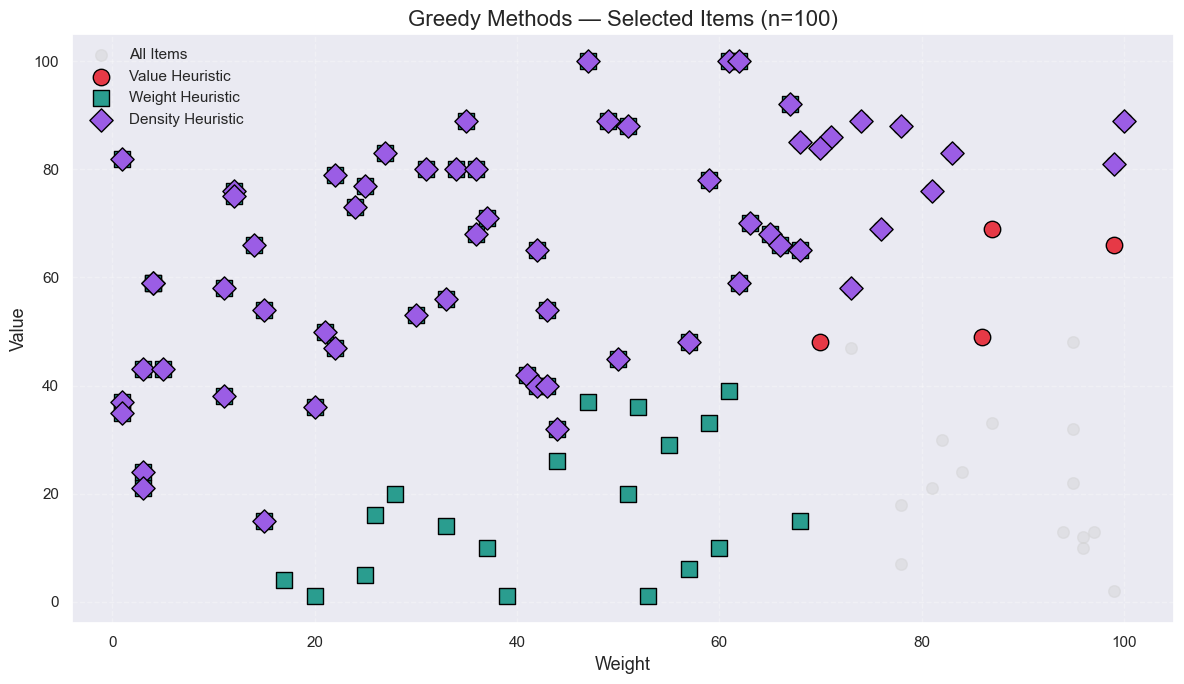


      GREEDY RESULTS (n=150)


=== Greedy by Value (n=150) ===
Value: 5621
Weight Used: 3545/3545
Items Selected: [33, 77, 93, 134, 115, 127, 105, 107, 130, 113, 74, 11, 12, 19, 34, 9, 17, 145, 98, 81, 6, 32, 73, 132, 20, 136, 27, 29, 61, 96, 90, 23, 117, 88, 50, 82, 47, 119, 24, 10, 28, 101, 106, 83, 85, 3, 4, 131, 15, 42, 67, 142, 2, 31, 104, 128, 125, 14, 64, 94, 123, 141, 44, 69, 51, 57, 78, 89, 149, 109, 137, 35, 100, 30, 86, 133, 124, 126]
Runtime: 6e-05 s

=== Greedy by Weight (n=150) ===
Value: 5180
Weight Used: 3545/3545
Items Selected: [3, 126, 64, 135, 13, 86, 14, 71, 104, 108, 30, 124, 133, 100, 110, 82, 111, 32, 61, 80, 17, 51, 28, 37, 149, 57, 148, 5, 20, 94, 40, 90, 103, 12, 38, 54, 68, 41, 142, 23, 87, 112, 85, 39, 96, 146, 11, 145, 50, 109, 1, 47, 79, 46, 123, 147, 120, 121, 128, 73, 98, 137, 144, 125, 140, 84, 4, 62, 99, 115, 18, 58, 139, 56, 102, 7, 78, 66, 119, 113, 6, 93, 105, 141, 107, 92, 25, 91, 95, 130, 2, 59, 83, 8, 36, 53, 9, 43, 27, 44, 75, 116, 134, 132, 2

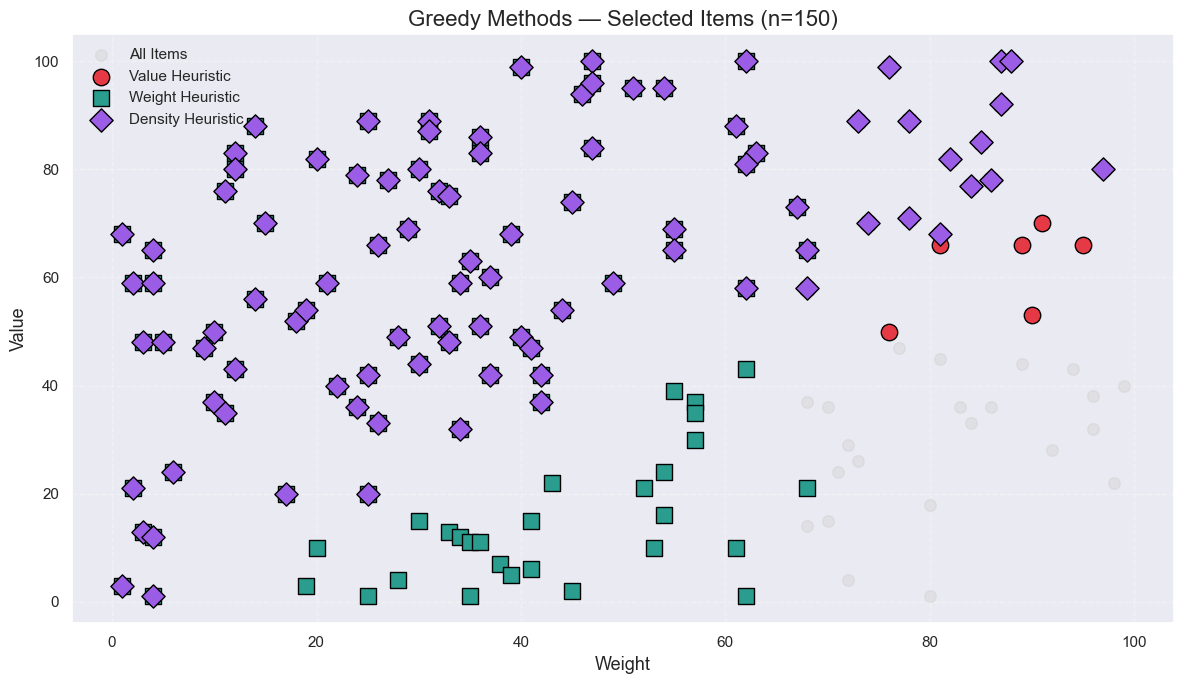

In [90]:
# === GREEDY METHODS (Unified Style Matching DP Plots) ===

for row in greedy_results:
    n = row["n"]
    items, capacity = datasets[n]

    print("\n==============================")
    print(f"      GREEDY RESULTS (n={n})")
    print("==============================\n")

    # ---- PRINT result blocks (same formatting as DP) ----
    print_result_block(
        f"Greedy by Value (n={n})",
        row["gv_val"],
        weight_of_solution(items, row["gv_sol"]),
        capacity,
        row["gv_sol"],
        row["gv_time"]
    )

    print_result_block(
        f"Greedy by Weight (n={n})",
        row["gw_val"],
        weight_of_solution(items, row["gw_sol"]),
        capacity,
        row["gw_sol"],
        row["gw_time"]
    )

    print_result_block(
        f"Greedy by Ratio (n={n})",
        row["gr_val"],
        weight_of_solution(items, row["gr_sol"]),
        capacity,
        row["gr_sol"],
        row["gr_time"]
    )

    # =====================================================
    #   COMBINED SCATTER (DP-style visualization)
    # =====================================================

    plt.figure(figsize=(12, 7))

    # --- All items (light background layer) ---
    all_w = [w for v, w, idx in items]
    all_v = [v for v, w, idx in items]
    plt.scatter(all_w, all_v, s=70, color="#d0d0d0", label="All Items", alpha=0.4)

    # === EXACT SAME STYLE USED IN DP SECTION ===
    # Selected items highlighted with outline

    # Greedy by Value
    gv_w = [items[i][1] for i in row["gv_sol"]]
    gv_v = [items[i][0] for i in row["gv_sol"]]
    plt.scatter(
        gv_w, gv_v, s=140, color="#e63946", edgecolor="black",
        label="Value Heuristic"
    )

    # Greedy by Weight
    gw_w = [items[i][1] for i in row["gw_sol"]]
    gw_v = [items[i][0] for i in row["gw_sol"]]
    plt.scatter(
        gw_w, gw_v, s=140, color="#2a9d8f", marker="s",
        edgecolor="black", label="Weight Heuristic"
    )

    # Greedy by Ratio
    gr_w = [items[i][1] for i in row["gr_sol"]]
    gr_v = [items[i][0] for i in row["gr_sol"]]
    plt.scatter(
        gr_w, gr_v, s=140, color="#9b5de5", marker="D",
        edgecolor="black", label="Density Heuristic"
    )

    # Capacity vertical line
    # plt.axvline(
    #     capacity, linestyle="--", color="black", linewidth=1.4,
    #     label=f"Capacity = {capacity}"
    # )

    # --- DP-style formatting ---
    plt.title(f"Greedy Methods — Selected Items (n={n})", fontsize=16)
    plt.xlabel("Weight", fontsize=13)
    plt.ylabel("Value", fontsize=13)
    plt.grid(alpha=0.3, linestyle="--")
    plt.legend(framealpha=0.9)
    plt.tight_layout()
    plt.show()


## Dynamic Programming Approaches

Dynamic programming provides exact solutions using overlapping subproblems.

### Variants
- Bottom-Up DP
- Top-Down DP with memoization

### Characteristics
- Pseudo-polynomial time complexity
- Guaranteed optimal solution
- Runtime increases with both `n` and knapsack capacity

DP serves as the **optimal reference** for evaluating solution quality.


In [91]:
dpbu_results = []

for n in sizes:
    items, capacity = datasets[n]

    t_dpbu, (dpbu_val, dpbu_sol, _) = timeit(dp_bottom_up_reconstruct)(items, capacity)

    dpbu_results.append({
        "n": n,
        "value": dpbu_val,
        "solution": dpbu_sol,
        "time": t_dpbu,
        "capacity": capacity
    })

print("DP Bottom-Up completed.")


DP Bottom-Up completed.



=== DP Bottom-Up (n=10) ===
Value: 390
Weight Used: 319/325
Items Selected: [0, 3, 4, 6, 8, 9]
Runtime: 0.001773 s


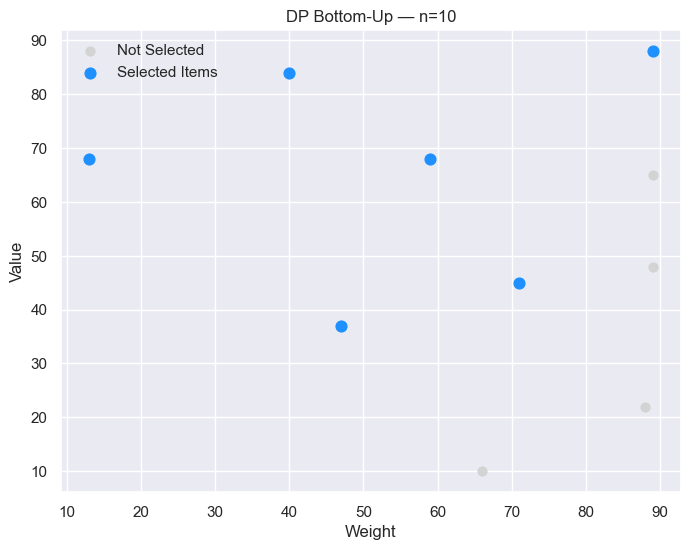


=== DP Bottom-Up (n=20) ===
Value: 892
Weight Used: 539/539
Items Selected: [1, 2, 4, 6, 9, 10, 11, 12, 15, 17, 18, 19]
Runtime: 0.006235 s


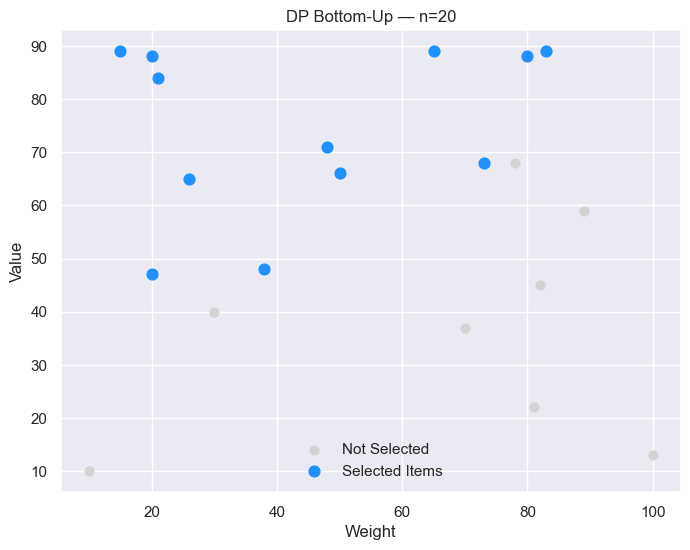


=== DP Bottom-Up (n=25) ===
Value: 1116
Weight Used: 581/594
Items Selected: [0, 1, 3, 6, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 24]
Runtime: 0.009164 s


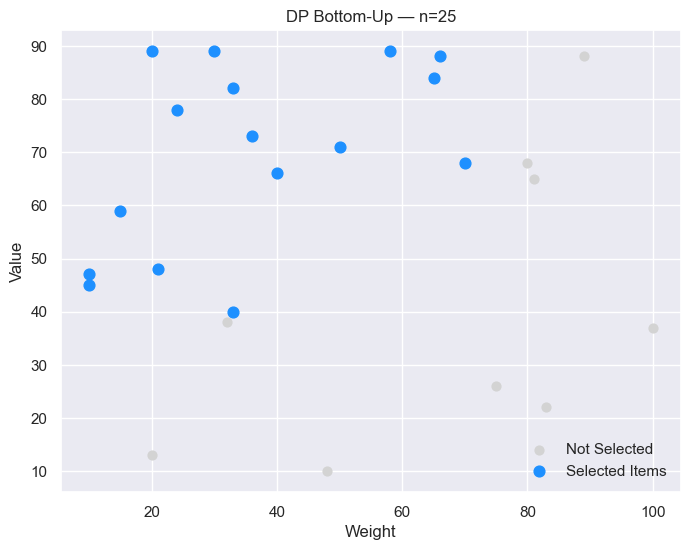


=== DP Bottom-Up (n=60) ===
Value: 2433
Weight Used: 1507/1514
Items Selected: [0, 2, 3, 4, 6, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 24, 27, 28, 29, 31, 32, 33, 34, 35, 37, 40, 42, 44, 47, 48, 49, 50, 51, 54, 56]
Runtime: 0.066715 s


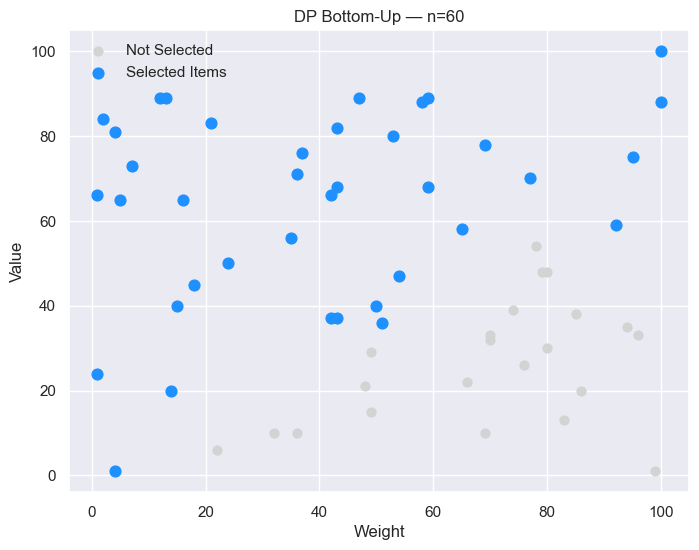


=== DP Bottom-Up (n=100) ===
Value: 4036
Weight Used: 2503/2503
Items Selected: [0, 2, 3, 4, 6, 8, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21, 23, 24, 26, 27, 28, 29, 31, 32, 33, 34, 35, 39, 40, 42, 44, 46, 47, 48, 50, 51, 53, 57, 61, 63, 64, 67, 68, 69, 70, 73, 74, 77, 78, 80, 81, 82, 85, 86, 88, 89, 90, 93, 94, 96, 98]
Runtime: 0.144142 s


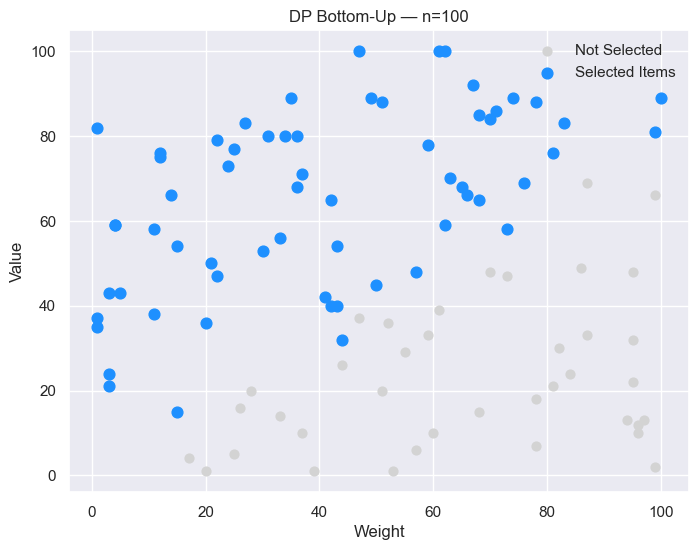


=== DP Bottom-Up (n=150) ===
Value: 6001
Weight Used: 3545/3545
Items Selected: [1, 2, 3, 4, 6, 9, 10, 11, 12, 13, 14, 17, 18, 19, 20, 23, 24, 27, 28, 29, 30, 31, 32, 33, 34, 37, 40, 41, 42, 44, 46, 47, 50, 51, 57, 61, 64, 68, 69, 71, 73, 74, 77, 78, 80, 81, 82, 83, 85, 86, 88, 90, 93, 94, 96, 98, 99, 100, 101, 102, 103, 104, 105, 107, 109, 110, 111, 112, 113, 115, 117, 119, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 135, 136, 137, 140, 141, 142, 145, 146, 149]
Runtime: 0.402999 s


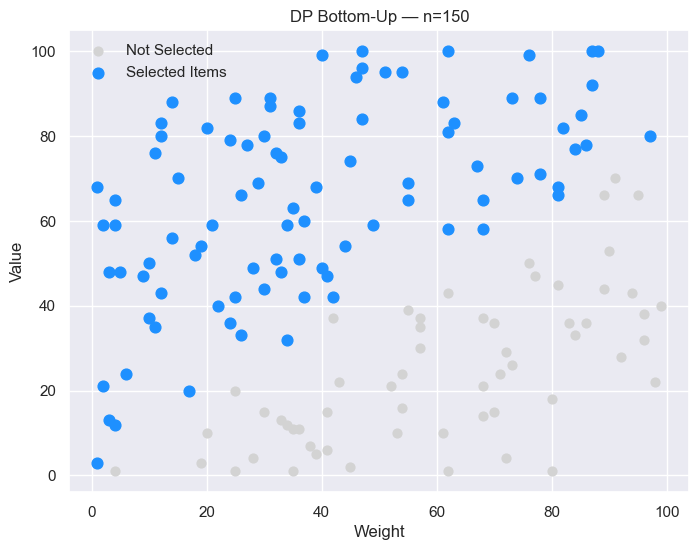

In [92]:
for row in dpbu_results:
    n = row["n"]
    items, capacity = datasets[n]

    print_result_block(
        f"DP Bottom-Up (n={n})",
        row["value"],
        weight_of_solution(items, row["solution"]),
        capacity,
        row["solution"],
        row["time"]
    )

    plot_selected_items(items, row["solution"], f"DP Bottom-Up — n={n}")


In [93]:
dptd_results = []

for n in sizes:
    items, capacity = datasets[n]

    t_dptd, (dptd_val, dptd_sol) = timeit(dp_top_down_reconstruct)(items, capacity)

    dptd_results.append({
        "n": n,
        "value": dptd_val,
        "solution": dptd_sol,
        "time": t_dptd,
        "capacity": capacity
    })

print("DP Top-Down completed.")


DP Top-Down completed.



=== DP Top-Down (n=10) ===
Value: 390
Weight Used: 319/325
Items Selected: [0, 3, 4, 6, 8, 9]
Runtime: 0.000626 s


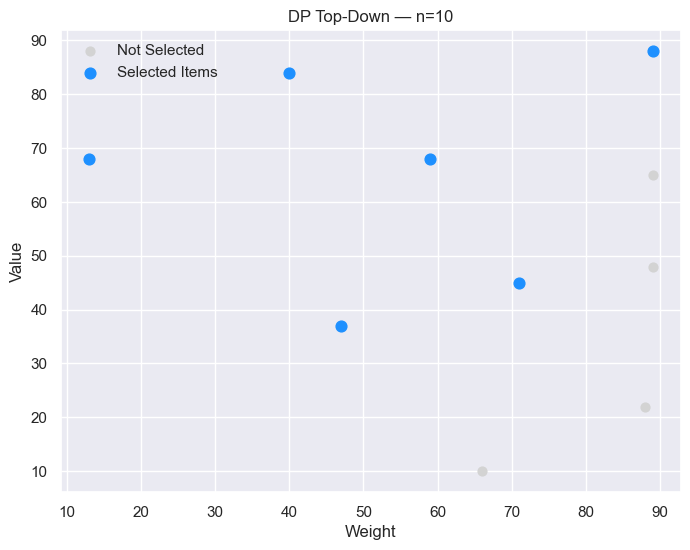


=== DP Top-Down (n=20) ===
Value: 892
Weight Used: 539/539
Items Selected: [1, 2, 4, 6, 9, 10, 11, 12, 15, 17, 18, 19]
Runtime: 0.007796 s


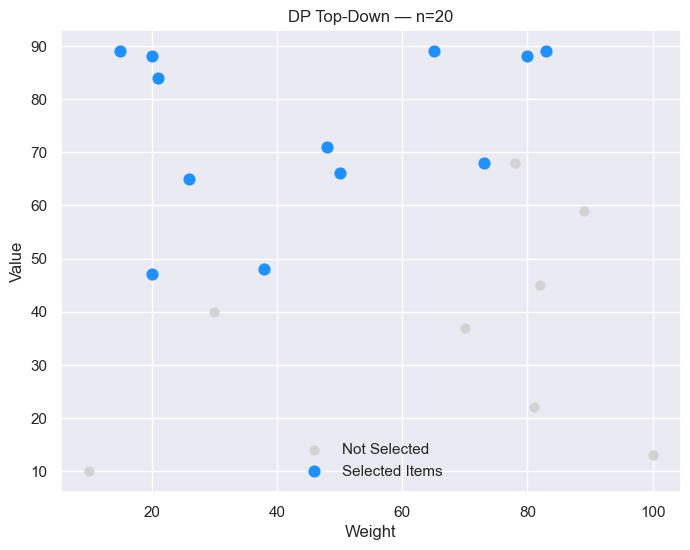


=== DP Top-Down (n=25) ===
Value: 1116
Weight Used: 581/594
Items Selected: [0, 1, 3, 6, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 24]
Runtime: 0.01967 s


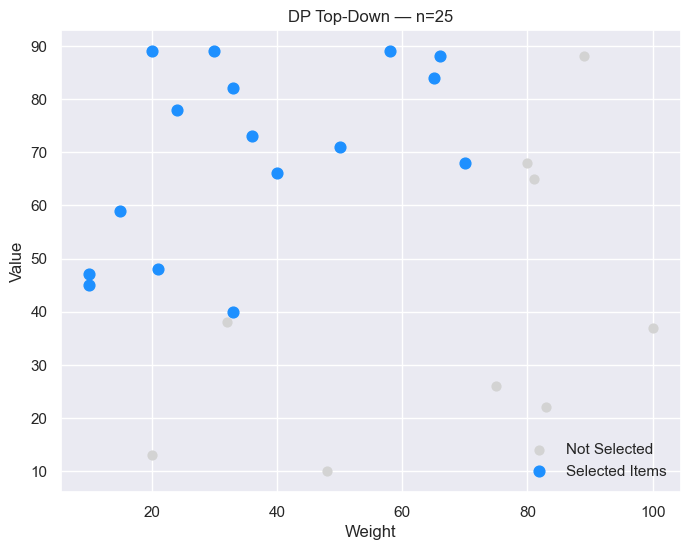


=== DP Top-Down (n=60) ===
Value: 2433
Weight Used: 1507/1514
Items Selected: [0, 2, 3, 4, 6, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 23, 24, 27, 28, 29, 31, 32, 33, 34, 35, 37, 40, 42, 44, 47, 48, 49, 50, 51, 54, 56]
Runtime: 0.12032 s


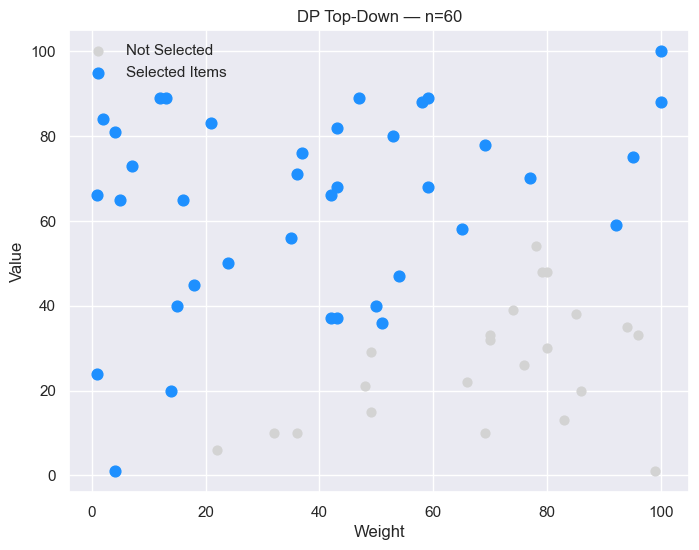


=== DP Top-Down (n=100) ===
Value: 4036
Weight Used: 2503/2503
Items Selected: [0, 2, 3, 4, 6, 8, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21, 23, 24, 26, 27, 28, 29, 31, 32, 33, 34, 35, 39, 40, 42, 44, 46, 47, 48, 50, 51, 53, 57, 61, 63, 64, 67, 68, 69, 70, 73, 74, 77, 78, 80, 81, 82, 85, 86, 88, 89, 90, 93, 94, 96, 98]
Runtime: 0.342912 s


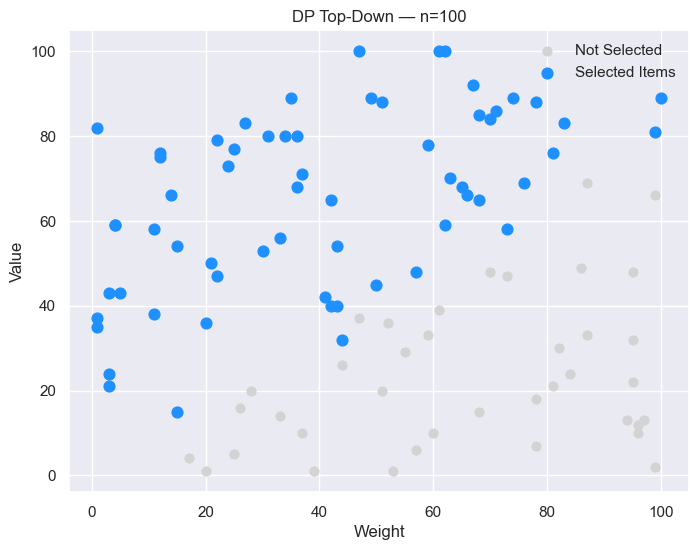


=== DP Top-Down (n=150) ===
Value: 6001
Weight Used: 3545/3545
Items Selected: [1, 2, 3, 4, 6, 9, 10, 11, 12, 13, 14, 17, 18, 19, 20, 23, 24, 27, 28, 29, 30, 31, 32, 33, 34, 37, 40, 41, 42, 44, 46, 47, 50, 51, 57, 61, 64, 68, 69, 71, 73, 74, 77, 78, 80, 81, 82, 83, 85, 86, 88, 90, 93, 94, 96, 98, 99, 100, 101, 102, 103, 104, 105, 107, 109, 110, 111, 112, 113, 115, 117, 119, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 134, 135, 136, 137, 140, 141, 142, 145, 146, 149]
Runtime: 1.159189 s


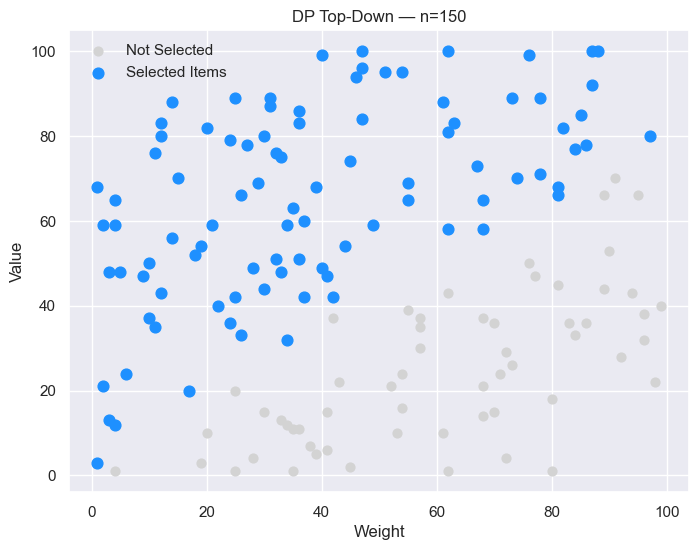

In [94]:
for row in dptd_results:
    n = row["n"]
    items, capacity = datasets[n]

    print_result_block(
        f"DP Top-Down (n={n})",
        row["value"],
        weight_of_solution(items, row["solution"]),
        capacity,
        row["solution"],
        row["time"]
    )

    plot_selected_items(items, row["solution"], f"DP Top-Down — n={n}")


## Branch and Bound

Branch and Bound explores the solution space selectively using upper bounds to prune suboptimal branches.

### Key Observations
- Worst-case exponential complexity
- Often much faster in practice
- Performance highly dependent on instance structure

This algorithm bridges the gap between brute force and heuristics.


In [95]:
bnb_results = []

for n in sizes:
    items, capacity = datasets[n]

    t_bnb, (bnb_val, bnb_sol,stats) = timeit(branch_and_bound)(items, capacity)

    bnb_results.append({
        "n": n,
        "value": bnb_val,
        "solution": bnb_sol,
        "time": t_bnb,
        "capacity": capacity
    })

print("Branch and Bound completed.")


Branch and Bound completed.



=== Branch and Bound (n=10) ===
Value: 390
Weight Used: 319/325
Items Selected: [3, 6, 4, 9, 8, 0]
Runtime: 0.000107 s


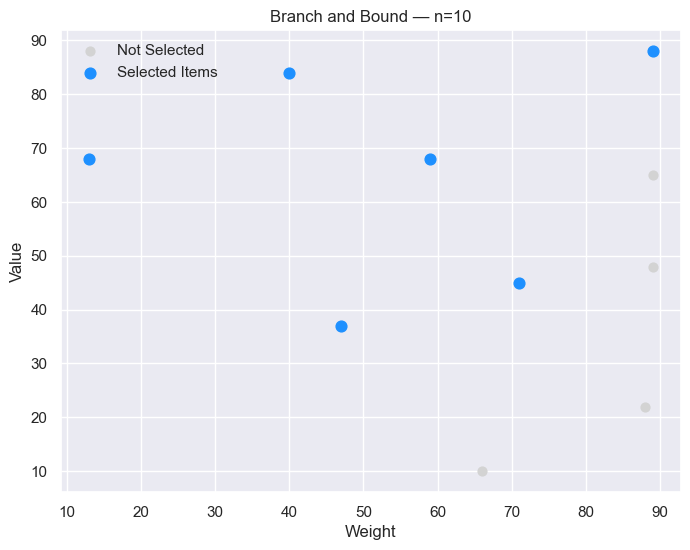


=== Branch and Bound (n=20) ===
Value: 892
Weight Used: 539/539
Items Selected: [19, 17, 6, 2, 18, 10, 11, 15, 1, 9, 12, 4]
Runtime: 0.000227 s


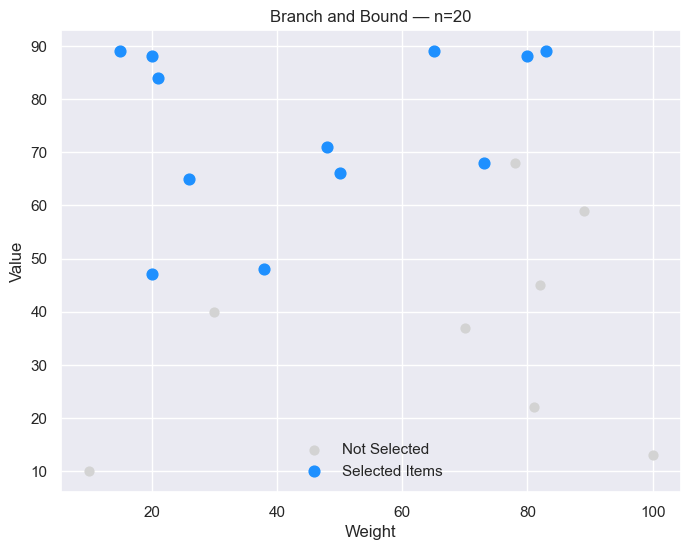


=== Branch and Bound (n=25) ===
Value: 1116
Weight Used: 581/594
Items Selected: [18, 0, 12, 14, 23, 11, 20, 1, 24, 15, 19, 10, 17, 6, 16, 3]
Runtime: 0.000312 s


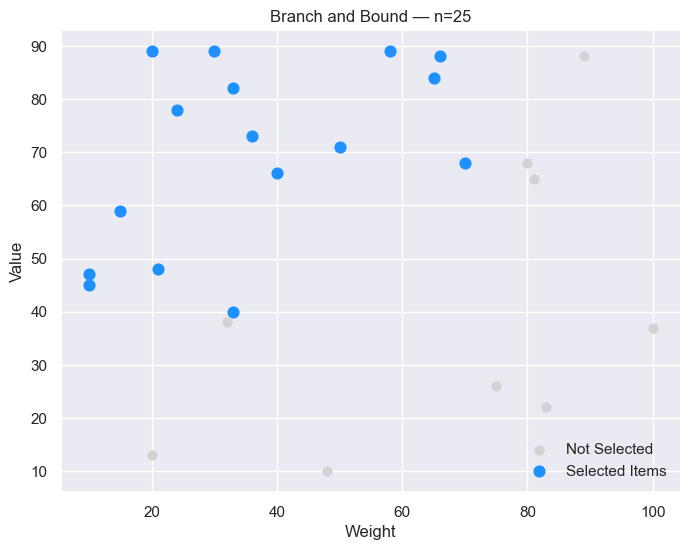


=== Branch and Bound (n=60) ===
Value: 2433
Weight Used: 1507/1514
Items Selected: [15, 6, 48, 27, 2, 24, 11, 19, 31, 32, 16, 0, 35, 50, 10, 20, 12, 51, 3, 42, 9, 29, 34, 37, 4, 23, 33, 28, 44, 8, 17, 18, 56, 40, 47, 49, 14, 54]
Runtime: 0.000919 s


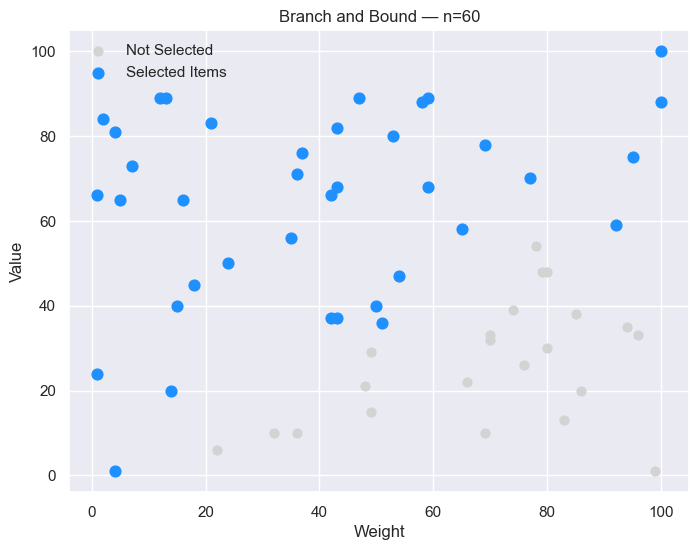


=== Branch and Bound (n=100) ===
Value: 4036
Weight Used: 2503/2503
Items Selected: [20, 8, 53, 14, 64, 63, 80, 48, 26, 82, 47, 44, 67, 78, 90, 21, 88, 73, 24, 61, 11, 35, 96, 29, 18, 33, 10, 3, 12, 70, 89, 9, 51, 93, 77, 2, 74, 23, 57, 81, 98, 19, 6, 17, 28, 4, 68, 32, 39, 42, 31, 40, 94, 50, 16, 85, 0, 34, 86, 27, 69, 46]
Runtime: 0.001336 s


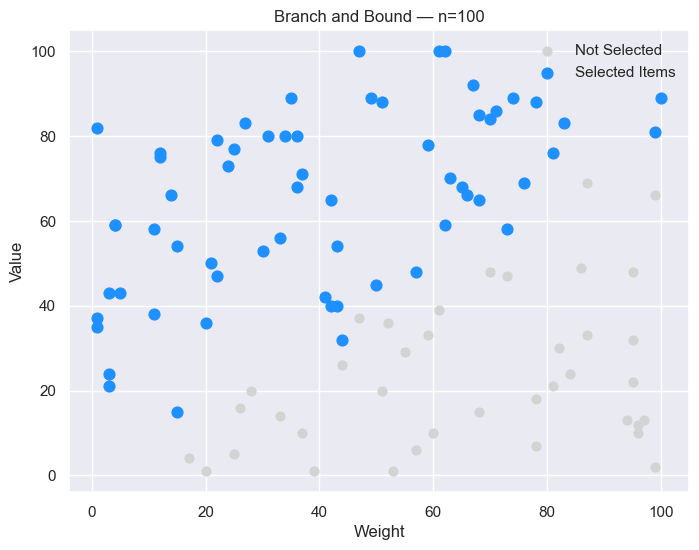


=== Branch and Bound (n=150) ===
Value: 6001
Weight Used: 3545/3545
Items Selected: [3, 64, 104, 86, 14, 135, 30, 32, 82, 61, 17, 133, 100, 28, 13, 20, 51, 124, 110, 80, 12, 90, 111, 71, 126, 23, 149, 11, 57, 94, 145, 96, 142, 115, 98, 85, 50, 73, 47, 93, 113, 105, 107, 40, 128, 6, 130, 112, 4, 123, 68, 119, 125, 134, 109, 103, 146, 1, 9, 137, 132, 27, 127, 41, 83, 78, 99, 19, 141, 2, 37, 33, 18, 34, 77, 140, 24, 74, 81, 102, 136, 31, 101, 46, 44, 88, 10, 117, 69, 131, 29, 42]
Runtime: 0.010572 s


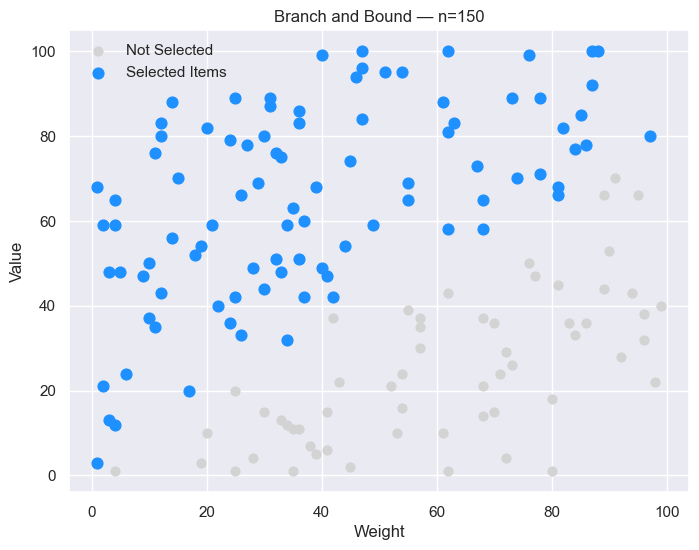

In [96]:
for row in bnb_results:
    n = row["n"]
    items, capacity = datasets[n]

    print_result_block(
        f"Branch and Bound (n={n})",
        row["value"],
        weight_of_solution(items, row["solution"]),
        capacity,
        row["solution"],
        row["time"]
    )

    plot_selected_items(items, row["solution"], f"Branch and Bound — n={n}")

## Runtime Analysis

Measured runtimes are collected for each algorithm across increasing problem sizes.

### Evaluation Goals
- Observe practical scalability
- Compare empirical runtime growth
- Contrast theoretical complexity with observed behavior

Log-scale plots are used to better illustrate growth trends.


In [97]:
# === RUNTIME COMPARISON TABLE ===

bf_time_map = {r["n"]: r["time"] for r in results_bruteforce}

final_df = pd.DataFrame({
    "n": sizes,

    "Greedy Value":  [r["gv_time"] for r in greedy_results],
    "Greedy Weight": [r["gw_time"] for r in greedy_results],
    "Greedy Ratio":  [r["gr_time"] for r in greedy_results],

    "DP Bottom-Up":  [r["time"] for r in dpbu_results],
    "DP Top-Down":   [r["time"] for r in dptd_results],
    "Branch and Bound":   [r["time"] for r in bnb_results],

    # Brute force only where available
    "Brute Force":   [bf_time_map.get(n, None) for n in sizes],
})

final_df



,n,Greedy Value,Greedy Weight,Greedy Ratio,DP Bottom-Up,DP Top-Down,Branch and Bound,Brute Force
0,10,0.000012,0.000006,0.000007,0.001773,0.000626,0.000107,0.001109
1,20,0.000010,0.000009,0.000011,0.006235,0.007796,0.000227,2.472013
2,25,0.000014,0.000010,0.000014,0.009164,0.019670,0.000312,122.232937
3,60,0.000025,0.000024,0.000028,0.066715,0.120320,0.000919,NaN
4,100,0.000040,0.000039,0.000044,0.144142,0.342912,0.001336,NaN
5,150,0.000060,0.000058,0.000067,0.402999,1.159189,0.010572,NaN


In [98]:
# ===  (Compare All Algorithms at n) ===

dataset_tables = {}

for n in sizes:
    items, cap = datasets[n]

    rows = []

    # Greedy Value
    r = next(x for x in greedy_results if x["n"] == n)
    rows.append({
        "Algorithm": "Greedy Value",
        "Value": r["gv_val"],
        "Weight": weight_of_solution(items, r["gv_sol"]),
        "Time (s)": r["gv_time"]
    })

    # Greedy Weight
    rows.append({
        "Algorithm": "Greedy Weight",
        "Value": r["gw_val"],
        "Weight": weight_of_solution(items, r["gw_sol"]),
        "Time (s)": r["gw_time"]
    })

    # Greedy Ratio
    rows.append({
        "Algorithm": "Greedy Ratio",
        "Value": r["gr_val"],
        "Weight": weight_of_solution(items, r["gr_sol"]),
        "Time (s)": r["gr_time"]
    })

    # DP BU
    rdp = next(x for x in dpbu_results if x["n"] == n)
    rows.append({
        "Algorithm": "DP Bottom-Up",
        "Value": rdp["value"],
        "Weight": weight_of_solution(items, rdp["solution"]),
        "Time (s)": rdp["time"]
    })

    # DP TD
    rtd = next(x for x in dptd_results if x["n"] == n)
    rows.append({
        "Algorithm": "DP Top-Down",
        "Value": rtd["value"],
        "Weight": weight_of_solution(items, rtd["solution"]),
        "Time (s)": rtd["time"]
    })

    # Bnb
    rtd = next(x for x in bnb_results if x["n"] == n)
    rows.append({
        "Algorithm": "Branch and Bound",
        "Value": rtd["value"],
        "Weight": weight_of_solution(items, rtd["solution"]),
        "Time (s)": rtd["time"]
    })

    # Brute force
    if n <= 30:
        rbt = next(x for x in results_bruteforce if x["n"] == n)
        rows.append({
            "Algorithm": "Brute Force",
            "Value": rbt["value"],
            "Weight": rbt["weight"],
            "Time (s)": rbt["time"]
        })

    dataset_tables[n] = pd.DataFrame(rows)

dataset_tables


{10:           Algorithm  Value  Weight  Time (s)
 0      Greedy Value    373     290  0.000012
 1     Greedy Weight    312     296  0.000006
 2      Greedy Ratio    390     319  0.000007
 3      DP Bottom-Up    390     319  0.001773
 4       DP Top-Down    390     319  0.000626
 5  Branch and Bound    390     319  0.000107
 6       Brute Force    390     319  0.001109,
 20:           Algorithm  Value  Weight  Time (s)
 0      Greedy Value    800     533  0.000010
 1     Greedy Weight    802     486  0.000009
 2      Greedy Ratio    874     506  0.000011
 3      DP Bottom-Up    892     539  0.006235
 4       DP Top-Down    892     539  0.007796
 5  Branch and Bound    892     539  0.000227
 6       Brute Force    892     539  2.472013,
 25:           Algorithm  Value  Weight    Time (s)
 0      Greedy Value   1012     591    0.000014
 1     Greedy Weight   1021     545    0.000010
 2      Greedy Ratio   1099     563    0.000014
 3      DP Bottom-Up   1116     581    0.009164
 4       D

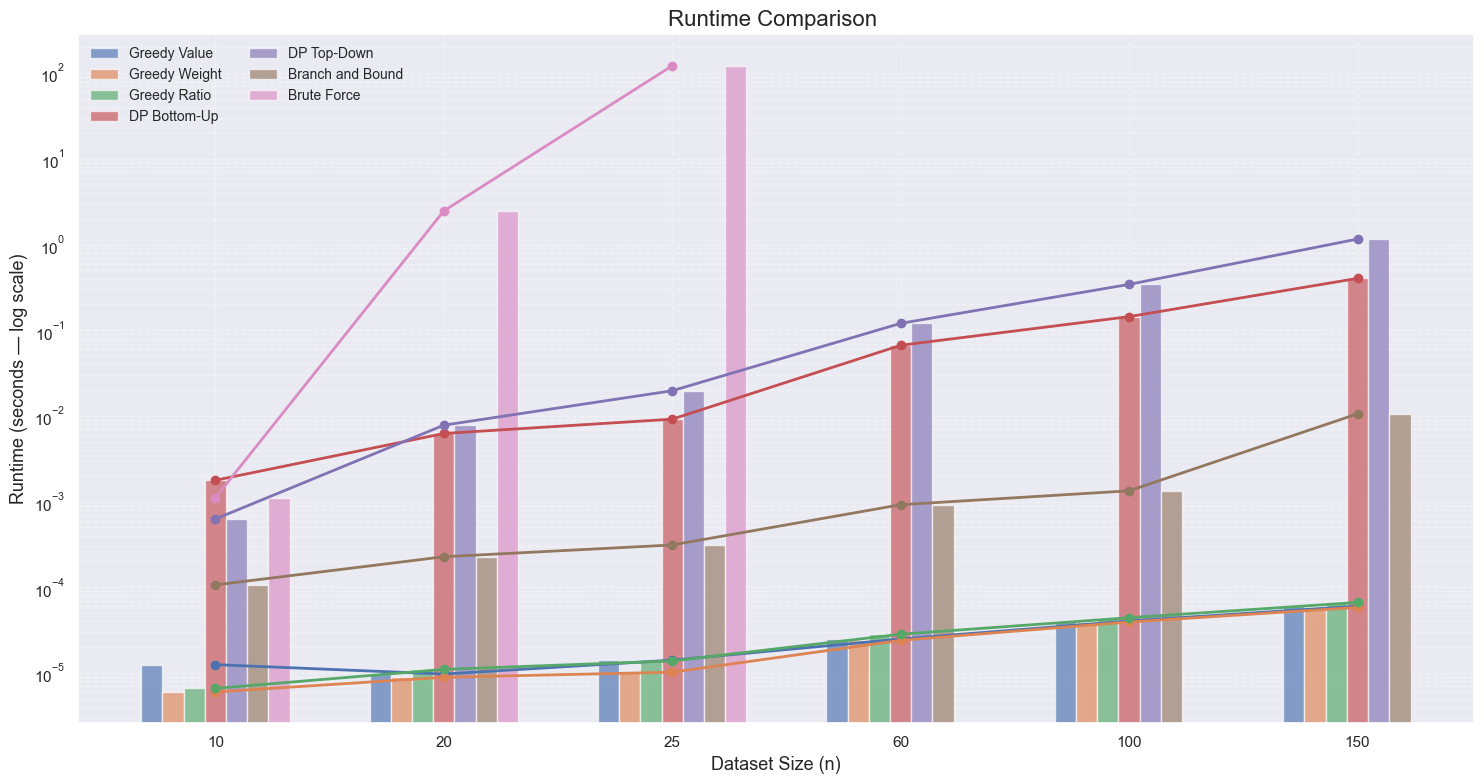

In [99]:

plt.figure(figsize=(15,8))

algorithms = list(final_df.columns[1:])
x = np.arange(len(sizes))  # the dataset sizes (30,60,100,150)
width = 0.65 / len(algorithms)  # bar width scaled by number of algorithms

# ----- BAR PLOT SECTION -----
for i, alg in enumerate(algorithms):
    offset = (i - len(algorithms)/2) * width + width/2
    plt.bar(x + offset, final_df[alg], width=width, alpha=0.65, label=alg)

# ----- LINE OVERLAY SECTION -----
for alg in algorithms:
    plt.plot(x, final_df[alg], marker="o", linewidth=2.0)

# ----- Aesthetics -----
plt.yscale("log")
plt.xticks(x, sizes)
plt.xlabel("Dataset Size (n)", fontsize=13)
plt.ylabel("Runtime (seconds — log scale)", fontsize=13)
plt.title("Runtime Comparison ", fontsize=16)

plt.grid(True, which="both", linestyle="--", alpha=0.35)
plt.legend(ncol=2, fontsize=10)
plt.tight_layout()
plt.show()

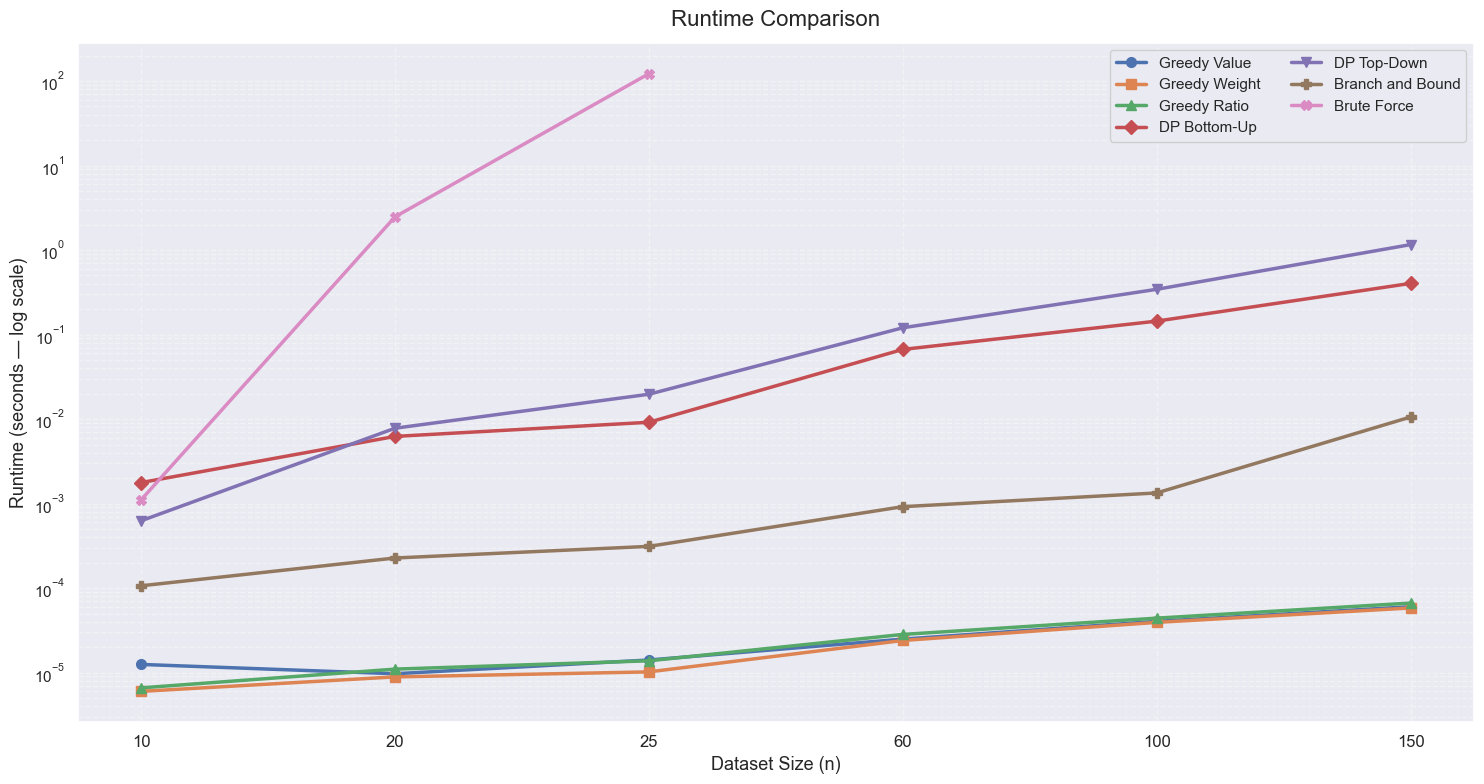

In [100]:
plt.figure(figsize=(15,8))

algorithms = list(final_df.columns[1:])
x = np.arange(len(sizes))  # dataset sizes (30,60,100,150)

markers = ["o", "s", "^", "D", "v", "P", "X", "*"]  # reused if algorithms > markers

# ----- LINE PLOT SECTION -----
for i, alg in enumerate(algorithms):
    plt.plot(
        x,
        final_df[alg],
        marker=markers[i % len(markers)],
        linewidth=2.5,
        markersize=7,
        label=alg
    )

# ----- Aesthetics -----
plt.yscale("log")
plt.xticks(x, sizes, fontsize=12)
plt.xlabel("Dataset Size (n)", fontsize=13)
plt.ylabel("Runtime (seconds — log scale)", fontsize=13)
plt.title("Runtime Comparison", fontsize=16, pad=12)

plt.grid(True, which="both", linestyle="--", alpha=0.35)
plt.legend(
    fontsize=11,
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    ncol=2
)

plt.tight_layout()
plt.show()


## Solution Quality Comparison

Solution quality is evaluated relative to the optimal solution obtained via
Dynamic Programming.

### Metrics
- Absolute value comparison
- Relative error

This highlights the cost of speed when using heuristics.


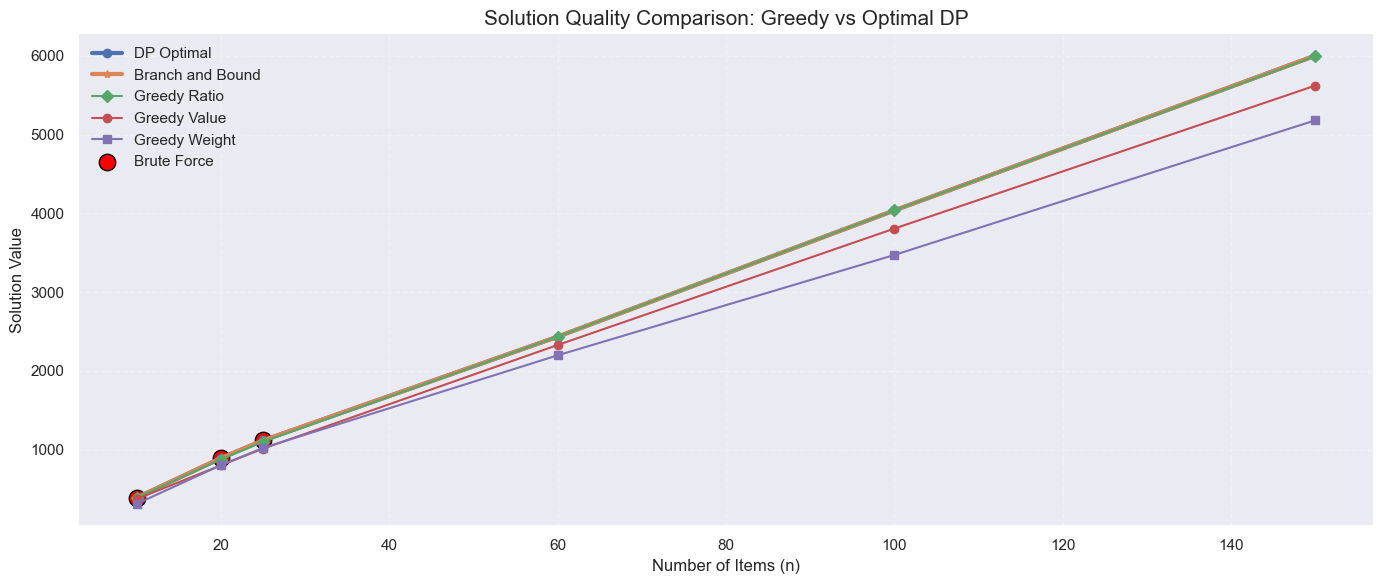

In [104]:
# SOLUTION QUALITY COMPARISON 

plt.figure(figsize=(14,6))

# --- DP Bottom-Up (Optimal baseline) ---
plt.plot(
    sizes,
    [r["value"] for r in dpbu_results],
    marker="o", linewidth=3,
    label="DP Optimal"
)

plt.plot(
    sizes,
    [r["value"] for r in bnb_results],
    marker="*", linewidth=3,
    label="Branch and Bound"
)

# --- Greedy methods ---
plt.plot(
    sizes,
    [r["gr_val"] for r in greedy_results],
    marker="D",
    label="Greedy Ratio"
)

plt.plot(
    sizes,
    [r["gv_val"] for r in greedy_results],
    marker="o",
    label="Greedy Value"
)

plt.plot(
    sizes,
    [r["gw_val"] for r in greedy_results],
    marker="s",
    label="Greedy Weight"
)

# --- Brute Force (only where computed) ---
for bf in results_bruteforce:
    plt.scatter(
        bf["n"], bf["value"],
        s=140, color="red", edgecolor="black",
        label="Brute Force" if bf == results_bruteforce[0] else ""
    )

# --- Formatting ---
plt.xlabel("Number of Items (n)", fontsize=12)
plt.ylabel("Solution Value", fontsize=12)
plt.title("Solution Quality Comparison: Greedy vs Optimal DP", fontsize=15)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


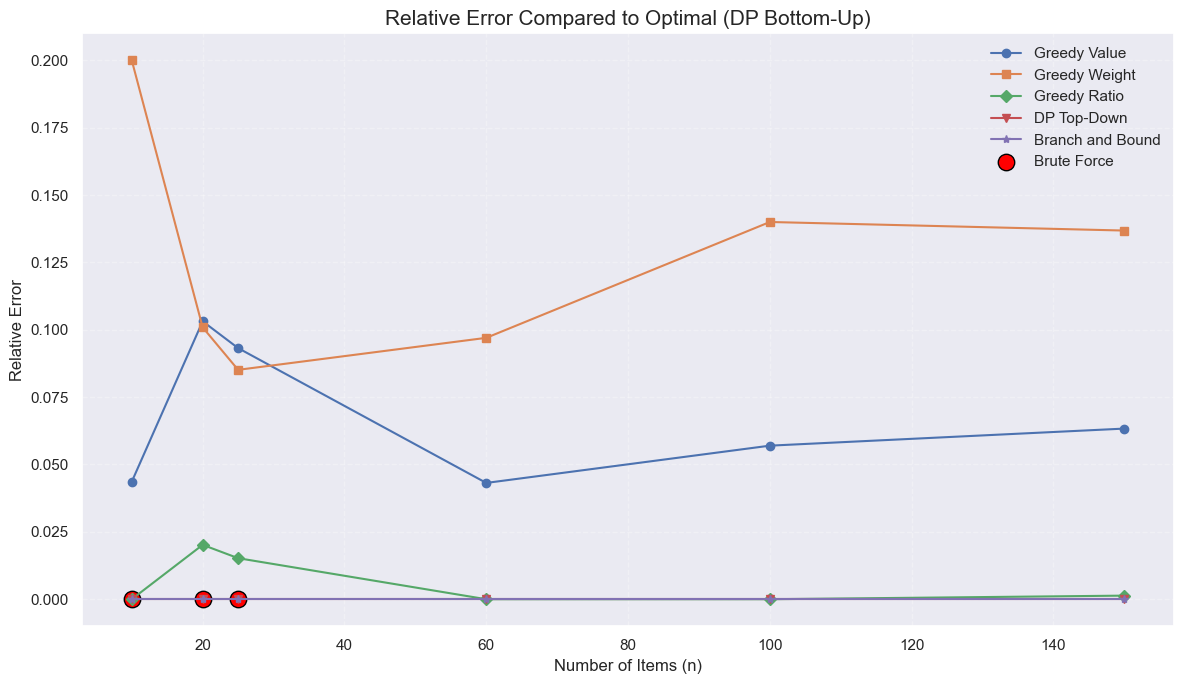

In [103]:
# === RELATIVE ERROR PLOT (quality gap vs optimal DP BU) ===

# Map optimal DP values by dataset size
dp_opt_map = {r["n"]: r["value"] for r in dpbu_results}

def relative_error(values):
    return [(dp_opt_map[n] - values[i]) / dp_opt_map[n]
            for i, n in enumerate(sizes)]

plt.figure(figsize=(12,7))

# --- Greedy methods ---
plt.plot(
    sizes,
    relative_error([r["gv_val"] for r in greedy_results]),
    marker="o", label="Greedy Value"
)

plt.plot(
    sizes,
    relative_error([r["gw_val"] for r in greedy_results]),
    marker="s", label="Greedy Weight"
)

plt.plot(
    sizes,
    relative_error([r["gr_val"] for r in greedy_results]),
    marker="D", label="Greedy Ratio"
)

# --- DP Top-Down vs Optimal ---
plt.plot(
    sizes,
    relative_error([r["value"] for r in dptd_results]),
    marker="v", label="DP Top-Down"
)

# --- bnb vs Optimal ---
plt.plot(
    sizes,
    relative_error([r["value"] for r in bnb_results]),
    marker="*", label="Branch and Bound"
)

# --- Brute Force points (only where available) ---
for bf in results_bruteforce:
    n = bf["n"]
    err = (dp_opt_map[n] - bf["value"]) / dp_opt_map[n]
    plt.scatter(
        n, err,
        s=140, color="red", edgecolor="black",
        label="Brute Force" if n == results_bruteforce[0]["n"] else ""
    )

# --- Plot formatting ---
plt.title("Relative Error Compared to Optimal (DP Bottom-Up)", fontsize=15)
plt.xlabel("Number of Items (n)", fontsize=12)
plt.ylabel("Relative Error", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


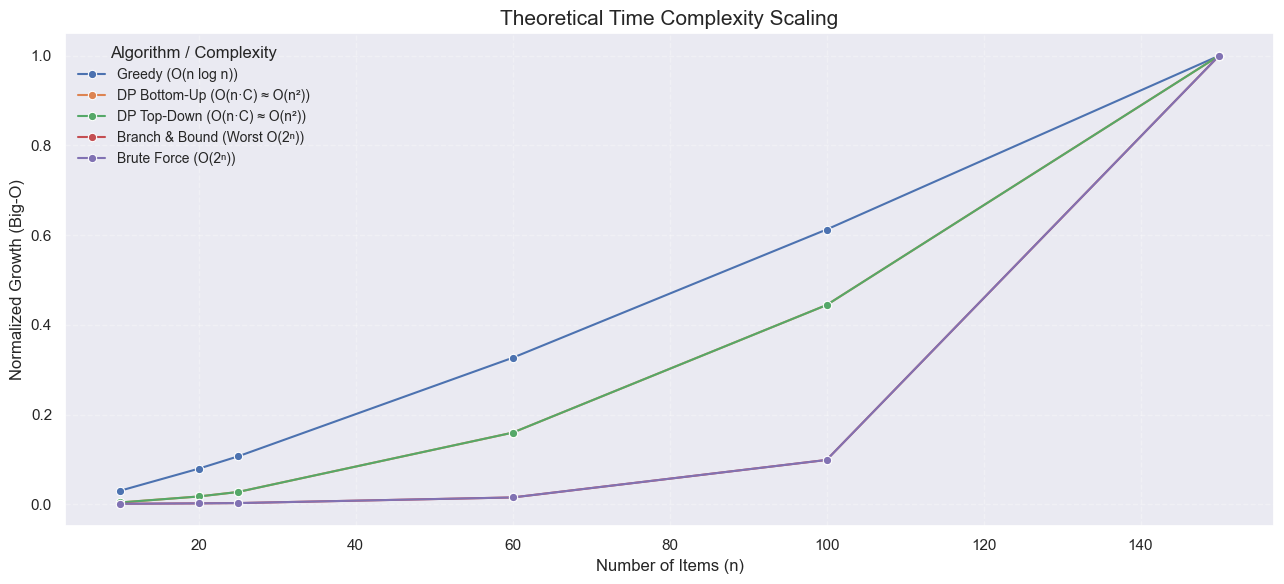

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Dataset sizes from analysis notebook
# -----------------------------
n_vals = np.array(sizes)

# -----------------------------
# Define theoretical complexities
# -----------------------------
complexity_df = pd.DataFrame({
    "n": n_vals,

    # Greedy (sorting-based)
    "Greedy (O(n log n))": n_vals * np.log2(n_vals),

    # DP methods (capacity proportional → approx n²)
    "DP Bottom-Up (O(n·C) ≈ O(n²))": n_vals**2,
    "DP Top-Down (O(n·C) ≈ O(n²))": n_vals**2,

    # Branch & Bound (exponential worst case, scaled)
    "Branch & Bound (Worst O(2ⁿ))": 2**(n_vals / n_vals.max() * 10),

    # Brute Force (pure exponential)
    "Brute Force (O(2ⁿ))": 2**(n_vals / n_vals.max() * 10)
})

# -----------------------------
# Normalize (visual comparison only)
# -----------------------------
for col in complexity_df.columns[1:]:
    complexity_df[col] /= complexity_df[col].max()

# Convert to long format
df_complexity = complexity_df.melt(
    id_vars="n",
    var_name="Algorithm",
    value_name="Normalized Growth"
)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(13,6))
sns.lineplot(
    data=df_complexity,
    x="n",
    y="Normalized Growth",
    hue="Algorithm",
    marker="o"
)

plt.title("Theoretical Time Complexity Scaling", fontsize=15)
plt.xlabel("Number of Items (n)", fontsize=12)
plt.ylabel("Normalized Growth (Big-O)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Algorithm / Complexity", fontsize=10)
plt.tight_layout()
plt.show()
